In [48]:
import numpy as np
import pandas as pd

In [49]:
data=np.random.randint(20,90,10)

In [50]:
data

array([30, 72, 22, 50, 41, 81, 29, 71, 89, 52], dtype=int32)

In [51]:
data.mean()

np.float64(53.7)

In [52]:
np.median(data)

np.float64(51.0)

In [53]:
s1=pd.Series(data)
s1

0    30
1    72
2    22
3    50
4    41
5    81
6    29
7    71
8    89
9    52
dtype: int32

In [54]:
s1.mean()

np.float64(53.7)

In [55]:
s1.median()

np.float64(51.0)

In [56]:
s1.mode()

0    22
1    29
2    30
3    41
4    50
5    52
6    71
7    72
8    81
9    89
dtype: int32

In [57]:
s1.quantile(0.25)

np.float64(32.75)

In [58]:
s1.quantile(0.50)

np.float64(51.0)

In [59]:
s1.quantile(0.75)

np.float64(71.75)

In [60]:
s1.min()

np.int32(22)

In [61]:
s1.max()

np.int32(89)

In [62]:
df=pd.read_csv("C:/Users/DELL/Desktop/FBS/Data Science/Datasets/shoe_sales.csv")
df.head()

,date,brand,sold_qty
0,9/1/2023,Nike,24.0
1,9/1/2023,Adidas,14.0
2,9/2/2023,Nike,21.0
3,9/2/2023,Adidas,12.0
4,9/3/2023,Nike,18.0


In [63]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   date      60 non-null     str    
 1   brand     60 non-null     str    
 2   sold_qty  58 non-null     float64
dtypes: float64(1), str(2)
memory usage: 1.5 KB


In [64]:
df.describe()

,sold_qty
count,58.000000
mean,27.482759
std,88.519844
min,7.000000
25%,12.250000
50%,16.000000
75%,19.750000
max,689.000000


In [65]:
df['sold_qty'] = df['sold_qty'].fillna(df['sold_qty'].median())

In [66]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   date      60 non-null     str    
 1   brand     60 non-null     str    
 2   sold_qty  60 non-null     float64
dtypes: float64(1), str(2)
memory usage: 1.5 KB


In [67]:
import matplotlib.pyplot as plt

{'whiskers': [<matplotlib.lines.Line2D at 0x2353e7afb10>,
 'caps': [<matplotlib.lines.Line2D at 0x2353e7afd90>,
 'boxes': [<matplotlib.lines.Line2D at 0x2353e7af9d0>],
 'medians': [<matplotlib.lines.Line2D at 0x2353e808050>],
 'fliers': [<matplotlib.lines.Line2D at 0x2353e808190>],
 'means': []}

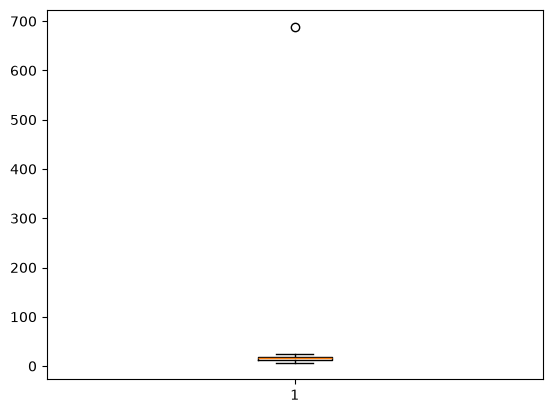

In [68]:
plt.boxplot(df['sold_qty'])

In [69]:
df2=df.copy()

In [70]:
q3 = df2['sold_qty'].quantile(0.75)
q1 = df2['sold_qty'].quantile(0.25)
q3, q1

(np.float64(19.25), np.float64(12.75))

In [71]:
iqr = q3 - q1
iqr

np.float64(6.5)

In [72]:
upper_bound = q3 + 1.5 * iqr
lower_bound = q1 - 1.5 * iqr
upper_bound, lower_bound

(np.float64(29.0), np.float64(3.0))

In [73]:
df[df['sold_qty']>upper_bound]

,date,brand,sold_qty
23,9/12/2023,Adidas,689.0


In [74]:
data =  df[(df['sold_qty']<=upper_bound) & (df['sold_qty']>=lower_bound)]
data.shape

(59, 3)

In [75]:
df.loc[df['sold_qty']>upper_bound, 'sold_qty'] =upper_bound

In [76]:
df[df['sold_qty']>upper_bound]

,date,brand,sold_qty


{'whiskers': [<matplotlib.lines.Line2D at 0x2353e82bb10>,
 'caps': [<matplotlib.lines.Line2D at 0x2353e82bd90>,
 'boxes': [<matplotlib.lines.Line2D at 0x2353e82b9d0>],
 'medians': [<matplotlib.lines.Line2D at 0x2353e868050>],
 'fliers': [<matplotlib.lines.Line2D at 0x2353e868190>],
 'means': []}

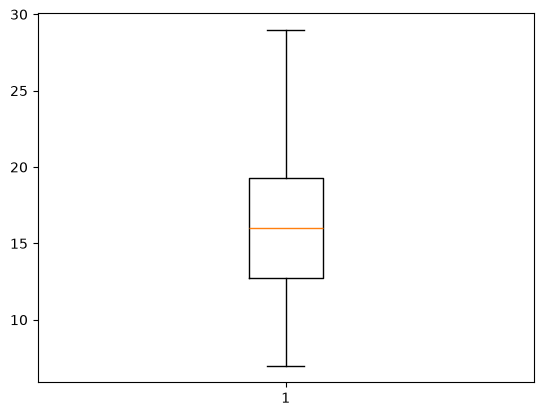

In [77]:
plt.boxplot(df['sold_qty'])

In [78]:
df=pd.read_csv("C:/Users/DELL/Desktop/FBS/Data Science/Datasets/shoe_sales.csv")
df.head()

,date,brand,sold_qty
0,9/1/2023,Nike,24.0
1,9/1/2023,Adidas,14.0
2,9/2/2023,Nike,21.0
3,9/2/2023,Adidas,12.0
4,9/3/2023,Nike,18.0


In [79]:
df['sold_qty'] = df['sold_qty'].fillna(df['sold_qty'].median())

In [80]:
std_val= df['sold_qty'].std()
mean_val = df['sold_qty'].mean()
std_val, mean_val

(np.float64(87.03139897059945), np.float64(27.1))

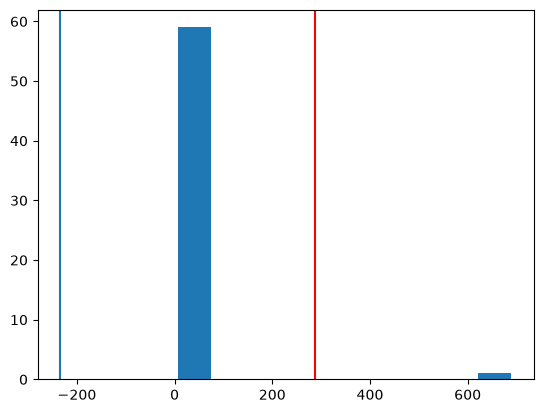

In [81]:
plt.hist(df['sold_qty'])
plt.axvline(mean_val+(3*std_val), color="red")
plt.axvline(mean_val-(3*std_val))
plt.show()